In [2]:
import mysql.connector

In [3]:

con = mysql.connector.connect(
    host="localhost",
    user="root",
    password="root",
    database="ecommerceanalyticsdb"

)

print("Connection established successfully!")

Connection established successfully!


In [4]:
cursor = con.cursor()

query = "select* from Ecommerce_Delivery"
cursor.execute(query)

In [5]:

results = cursor.fetchall()
for row in results:
    print(row)

(1, 101, datetime.date(2026, 1, 5), 'Electronics', 'Wireless Earbuds', 1, Decimal('2499.00'), 'UPI', 'Chennai', 'Delhivery', 3, 2, 'Delivered', Decimal('5.0'), 'Satisfied')
(2, 102, datetime.date(2026, 1, 6), 'Fashion', 'Running Shoes', 1, Decimal('3299.00'), 'Card', 'Bangalore', 'Blue Dart', 4, 4, 'Delivered', Decimal('4.5'), 'Satisfied')
(3, 103, datetime.date(2026, 1, 7), 'Grocery', 'Organic Rice', 2, Decimal('1800.00'), 'UPI', 'Coimbatore', 'Ecom Express', 3, 5, 'Delayed', Decimal('2.5'), 'Unsatisfied')
(4, 104, datetime.date(2026, 1, 8), 'Beauty', 'Face Serum', 2, Decimal('1598.00'), 'COD', 'Madurai', 'Delhivery', 3, 3, 'Delivered', Decimal('4.0'), 'Satisfied')
(5, 105, datetime.date(2026, 1, 9), 'Home & Kitchen', 'Mixer Grinder', 1, Decimal('4599.00'), 'Card', 'Chennai', 'Blue Dart', 4, 6, 'Delayed', Decimal('2.0'), 'Unsatisfied')
(6, 106, datetime.date(2026, 1, 10), 'Electronics', 'Smart Watch', 1, Decimal('5999.00'), 'UPI', 'Hyderabad', 'DTDC', 4, 4, 'Delivered', Decimal('4.5')

In [6]:

import pandas as pd

query = "select* from Ecommerce_Delivery;"

df = pd.read_sql(query, con)
print(df)


    Order_ID  Customer_ID  Order_Date Product_Category      Product_Name  \
0          1          101  2026-01-05      Electronics  Wireless Earbuds   
1          2          102  2026-01-06          Fashion     Running Shoes   
2          3          103  2026-01-07          Grocery      Organic Rice   
3          4          104  2026-01-08           Beauty        Face Serum   
4          5          105  2026-01-09   Home & Kitchen     Mixer Grinder   
..       ...          ...         ...              ...               ...   
95        96          196  2026-04-10      Electronics        Smartphone   
96        97          197  2026-04-11          Fashion          Sneakers   
97        98          198  2026-04-12          Grocery      Basmati Rice   
98        99          199  2026-04-13           Beauty     Skin Care Kit   
99       100          200  2026-04-14   Home & Kitchen   Electric Cooker   

    Quantity  Order_Amount Payment_Method        City Delivery_Partner  \
0          1 

C:\Users\acer\AppData\Local\Temp\ipykernel_15636\335660086.py:5: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, con)


In [7]:
df.shape
df.info()
df.isnull().sum()
df.duplicated().sum()
df.describe()
df.nunique()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                100 non-null    int64  
 1   Customer_ID             100 non-null    int64  
 2   Order_Date              100 non-null    object 
 3   Product_Category        100 non-null    str    
 4   Product_Name            100 non-null    str    
 5   Quantity                100 non-null    int64  
 6   Order_Amount            100 non-null    float64
 7   Payment_Method          100 non-null    str    
 8   City                    100 non-null    str    
 9   Delivery_Partner        100 non-null    str    
 10  Expected_Delivery_Days  100 non-null    int64  
 11  Actual_Delivery_Days    100 non-null    int64  
 12  Delivery_Status         100 non-null    str    
 13  Customer_Rating         100 non-null    float64
 14  Customer_Satisfaction   100 non-null    str    
dtypes

Order_ID                  100
Customer_ID               100
Order_Date                100
Product_Category            5
Product_Name               98
Quantity                    5
Order_Amount               56
Payment_Method              3
City                        7
Delivery_Partner            4
Expected_Delivery_Days      3
Actual_Delivery_Days        6
Delivery_Status             2
Customer_Rating             6
Customer_Satisfaction       3
dtype: int64

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

1. Revenue by Product Category

In [9]:
query = "SELECT Product_Category, Customer_Rating FROM Ecommerce_Delivery"

df = pd.read_sql(query, con)

df

C:\Users\acer\AppData\Local\Temp\ipykernel_15636\1549539154.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, con)


,Product_Category,Customer_Rating
0,Electronics,5.0
1,Fashion,4.5
2,Grocery,2.5
3,Beauty,4.0
4,Home & Kitchen,2.0
...,...,...
95,Electronics,5.0
96,Fashion,4.5
97,Grocery,2.5
98,Beauty,4.5


Violin Plot — Customer Rating by Category

In [10]:
query = "SELECT Product_Category, AVG(Order_Amount) AS Average_Amount, AVG(Customer_Rating) AS Average_Rating, AVG(Quantity) AS Average_Quantity FROM Ecommerce_Delivery GROUP BY Product_Category"

df = pd.read_sql(query, con)

df

C:\Users\acer\AppData\Local\Temp\ipykernel_15636\247546543.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, con)


,Product_Category,Average_Amount,Average_Rating,Average_Quantity
0,Electronics,6758.75,4.625,1.25
1,Fashion,2683.45,3.775,1.55
2,Grocery,1039.00,3.725,2.50
3,Beauty,1350.90,3.775,1.85
4,Home & Kitchen,3243.70,3.400,1.30


C:\Users\acer\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


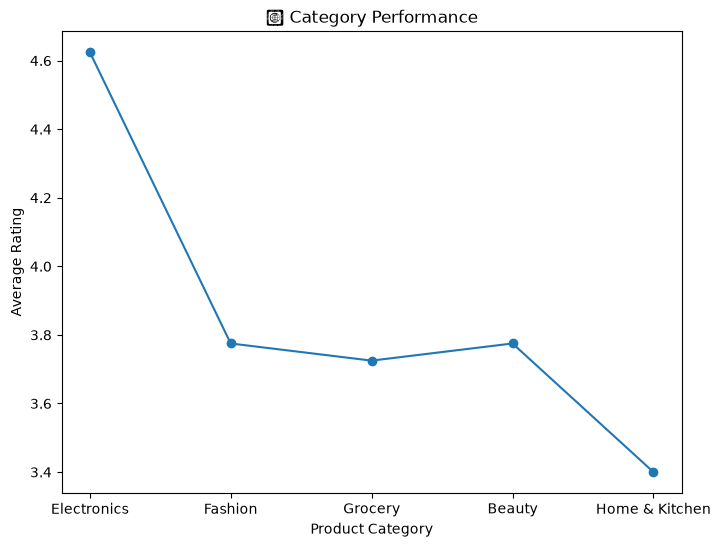

In [11]:
plt.figure(figsize=(8, 6))

plt.plot(df["Product_Category"], df["Average_Rating"], marker="o")

plt.title("🎯 Category Performance")
plt.xlabel("Product Category")
plt.ylabel("Average Rating")

plt.show()

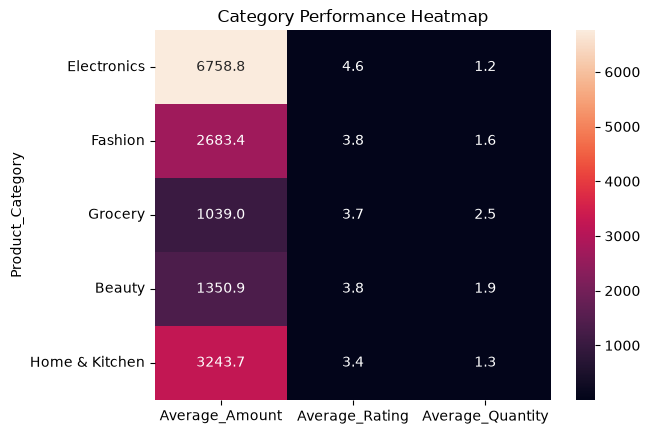

In [12]:
import seaborn as sns

df = df.set_index("Product_Category")

sns.heatmap(df, annot=True, fmt=".1f")

plt.title("Category Performance Heatmap")
plt.show()

In [13]:
query = "SELECT City, AVG(Expected_Delivery_Days) AS Expected_Days, AVG(Actual_Delivery_Days) AS Actual_Days FROM Ecommerce_Delivery GROUP BY City"

df = pd.read_sql(query, con)

df

C:\Users\acer\AppData\Local\Temp\ipykernel_15636\2135729393.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, con)


,City,Expected_Days,Actual_Days
0,Chennai,3.7600,3.8800
1,Bangalore,4.0667,4.6000
2,Coimbatore,3.5385,4.1538
3,Madurai,3.4667,4.5333
4,Hyderabad,3.7000,3.9000
5,Salem,3.5000,4.2500
6,Trichy,3.0000,3.5000


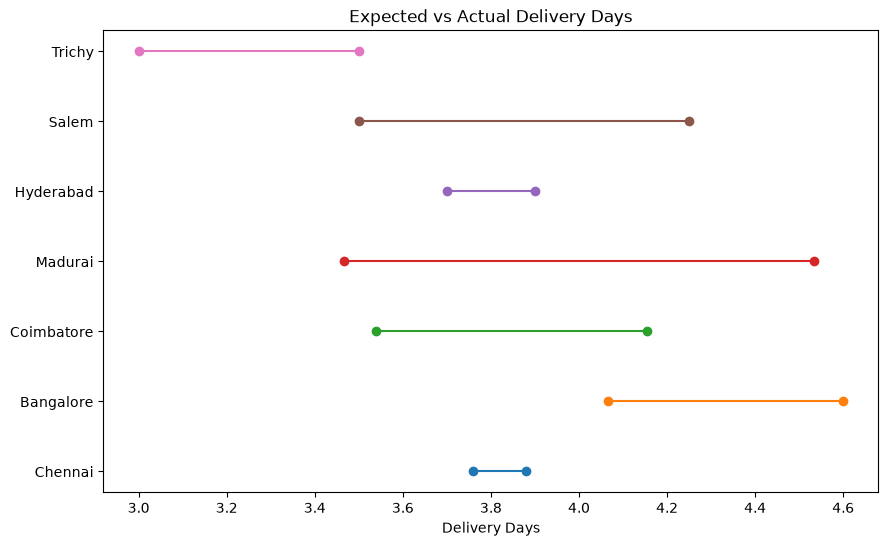

In [14]:
plt.figure(figsize=(10, 6))

for i in range(len(df)):
    plt.plot([df["Expected_Days"][i], df["Actual_Days"][i]], [df["City"][i], df["City"][i]], marker="o")

plt.title("Expected vs Actual Delivery Days")
plt.xlabel("Delivery Days")

plt.show()


In [15]:
query = "SELECT Product_Category, SUM(Order_Amount) AS Total_Sales FROM Ecommerce_Delivery GROUP BY Product_Category"

df = pd.read_sql(query, con)

df

C:\Users\acer\AppData\Local\Temp\ipykernel_15636\3178356770.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, con)


,Product_Category,Total_Sales
0,Electronics,135175.0
1,Fashion,53669.0
2,Grocery,20780.0
3,Beauty,27018.0
4,Home & Kitchen,64874.0


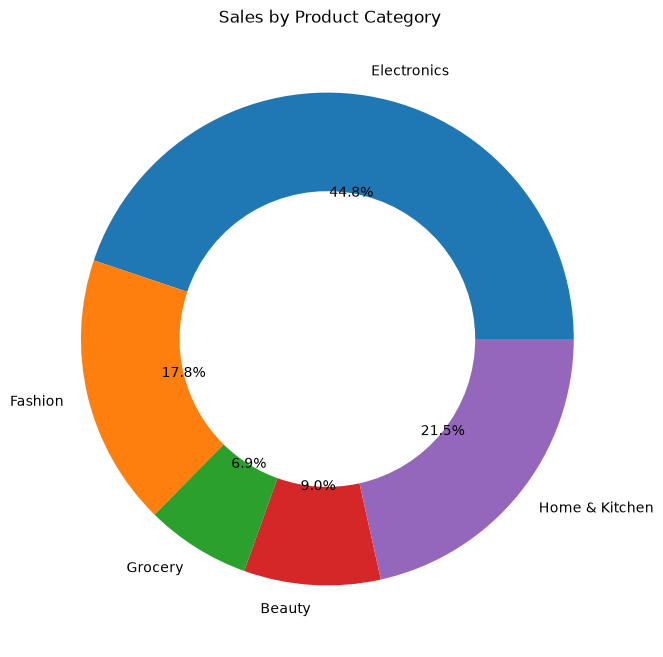

In [16]:
plt.figure(figsize=(8, 8))

plt.pie(df["Total_Sales"], labels=df["Product_Category"],
        autopct="%1.1f%%", wedgeprops={"width": 0.4})

plt.title(" Sales by Product Category")
plt.show()

In [17]:
query = "SELECT Delivery_Status, COUNT(*) AS Total_Orders FROM Ecommerce_Delivery GROUP BY Delivery_Status"

df = pd.read_sql(query, con)

df

C:\Users\acer\AppData\Local\Temp\ipykernel_15636\169268834.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, con)


,Delivery_Status,Total_Orders
0,Delivered,69
1,Delayed,31


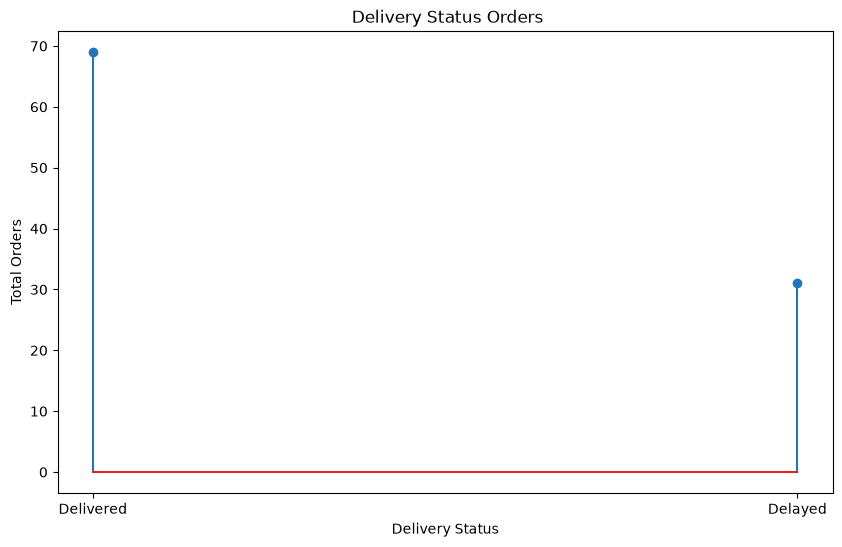

In [18]:
plt.figure(figsize=(10, 6))

plt.stem(df["Delivery_Status"], df["Total_Orders"])

plt.title(" Delivery Status Orders")
plt.xlabel("Delivery Status")
plt.ylabel("Total Orders")

plt.show()

In [19]:
query = "SELECT City, AVG(Actual_Delivery_Days) AS Average_Days, AVG(Customer_Rating) AS Average_Rating FROM Ecommerce_Delivery GROUP BY City"

df = pd.read_sql(query, con)

df

C:\Users\acer\AppData\Local\Temp\ipykernel_15636\2379422720.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, con)


,City,Average_Days,Average_Rating
0,Chennai,3.8800,4.32000
1,Bangalore,4.6000,3.70000
2,Coimbatore,4.1538,3.84615
3,Madurai,4.5333,3.26667
4,Hyderabad,3.9000,4.25000
5,Salem,4.2500,3.50000
6,Trichy,3.5000,3.90000


C:\Users\acer\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128205 (\N{ROUND PUSHPIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


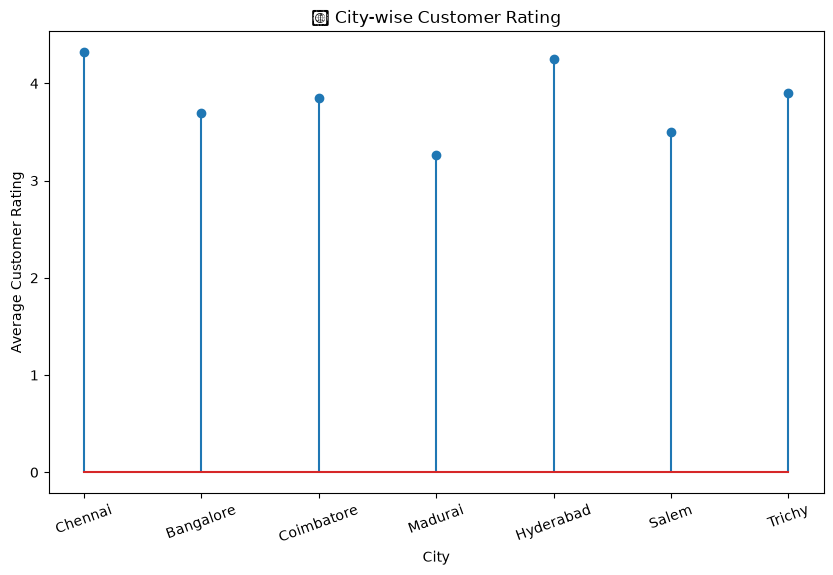

In [20]:
plt.figure(figsize=(10, 6))

plt.stem(df["City"], df["Average_Rating"])

plt.title("📍 City-wise Customer Rating")
plt.xlabel("City")
plt.ylabel("Average Customer Rating")

plt.xticks(rotation=20)
plt.show()

Ecommerce_Delivery
        │
        │ Order_ID
        ↓
Delivery_Partners
🟦 4-IN-1 DASHBOARD

🎻 Violin Plot → Category vs Customer Rating
🔗 Dumbbell Chart → Expected vs Actual Delivery
🫧 Bubble Chart → Quantity vs Order Amount
🍩 Donut Chart → Service Type

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

query = "SELECT e.Order_ID, e.Order_Date, e.Product_Category, e.Quantity, e.Order_Amount, e.Payment_Method, e.City, e.Expected_Delivery_Days, e.Actual_Delivery_Days, e.Delivery_Status, e.Customer_Rating, d.Delivery_Partner, d.Service_Type, d.Partner_Rating, d.Base_Delivery_Days, d.Service_City FROM Ecommerce_Delivery e INNER JOIN Delivery_Partners d ON e.Order_ID = d.Order_ID"

df = pd.read_sql(query, con)

df

C:\Users\acer\AppData\Local\Temp\ipykernel_15636\2697795543.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, con)


,Order_ID,Order_Date,Product_Category,Quantity,Order_Amount,Payment_Method,City,Expected_Delivery_Days,Actual_Delivery_Days,Delivery_Status,Customer_Rating,Delivery_Partner,Service_Type,Partner_Rating,Base_Delivery_Days,Service_City
0,1,2026-01-05,Electronics,1,2499.0,UPI,Chennai,3,2,Delivered,5.0,Delhivery,Standard Delivery,4.2,3,Chennai
1,2,2026-01-06,Fashion,1,3299.0,Card,Bangalore,4,4,Delivered,4.5,Blue Dart,Express Delivery,4.5,2,Bangalore
2,3,2026-01-07,Grocery,2,1800.0,UPI,Coimbatore,3,5,Delayed,2.5,Ecom Express,Standard Delivery,4.0,4,Hyderabad
3,4,2026-01-08,Beauty,2,1598.0,COD,Madurai,3,3,Delivered,4.0,DTDC,Express Delivery,4.1,3,Mumbai
4,5,2026-01-09,Home & Kitchen,1,4599.0,Card,Chennai,4,6,Delayed,2.0,Delhivery,Express Delivery,4.3,2,Delhi
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,2026-04-10,Electronics,1,21999.0,UPI,Chennai,4,4,Delivered,5.0,DTDC,Standard Delivery,4.1,4,Chennai
96,97,2026-04-11,Fashion,1,3999.0,COD,Salem,4,4,Delivered,4.5,Delhivery,Standard Delivery,4.1,3,Bangalore
97,98,2026-04-12,Grocery,2,1800.0,UPI,Trichy,3,5,Delayed,2.5,Blue Dart,Express Delivery,4.5,2,Hyderabad
98,99,2026-04-13,Beauty,1,2499.0,Card,Madurai,4,4,Delivered,4.5,Ecom Express,Standard Delivery,4.0,4,Mumbai


C:\Users\acer\AppData\Local\Temp\ipykernel_15636\3721941586.py:65: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\acer\AppData\Local\Temp\ipykernel_15636\3721941586.py:65: UserWarning: Glyph 128279 (\N{LINK SYMBOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\acer\AppData\Local\Temp\ipykernel_15636\3721941586.py:65: UserWarning: Glyph 129767 (\N{BUBBLES}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\acer\AppData\Local\Temp\ipykernel_15636\3721941586.py:65: UserWarning: Glyph 127849 (\N{DOUGHNUT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\acer\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127931 (\N{VIOLIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\acer\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128279 (\N{LINK SYMBOL}) mis

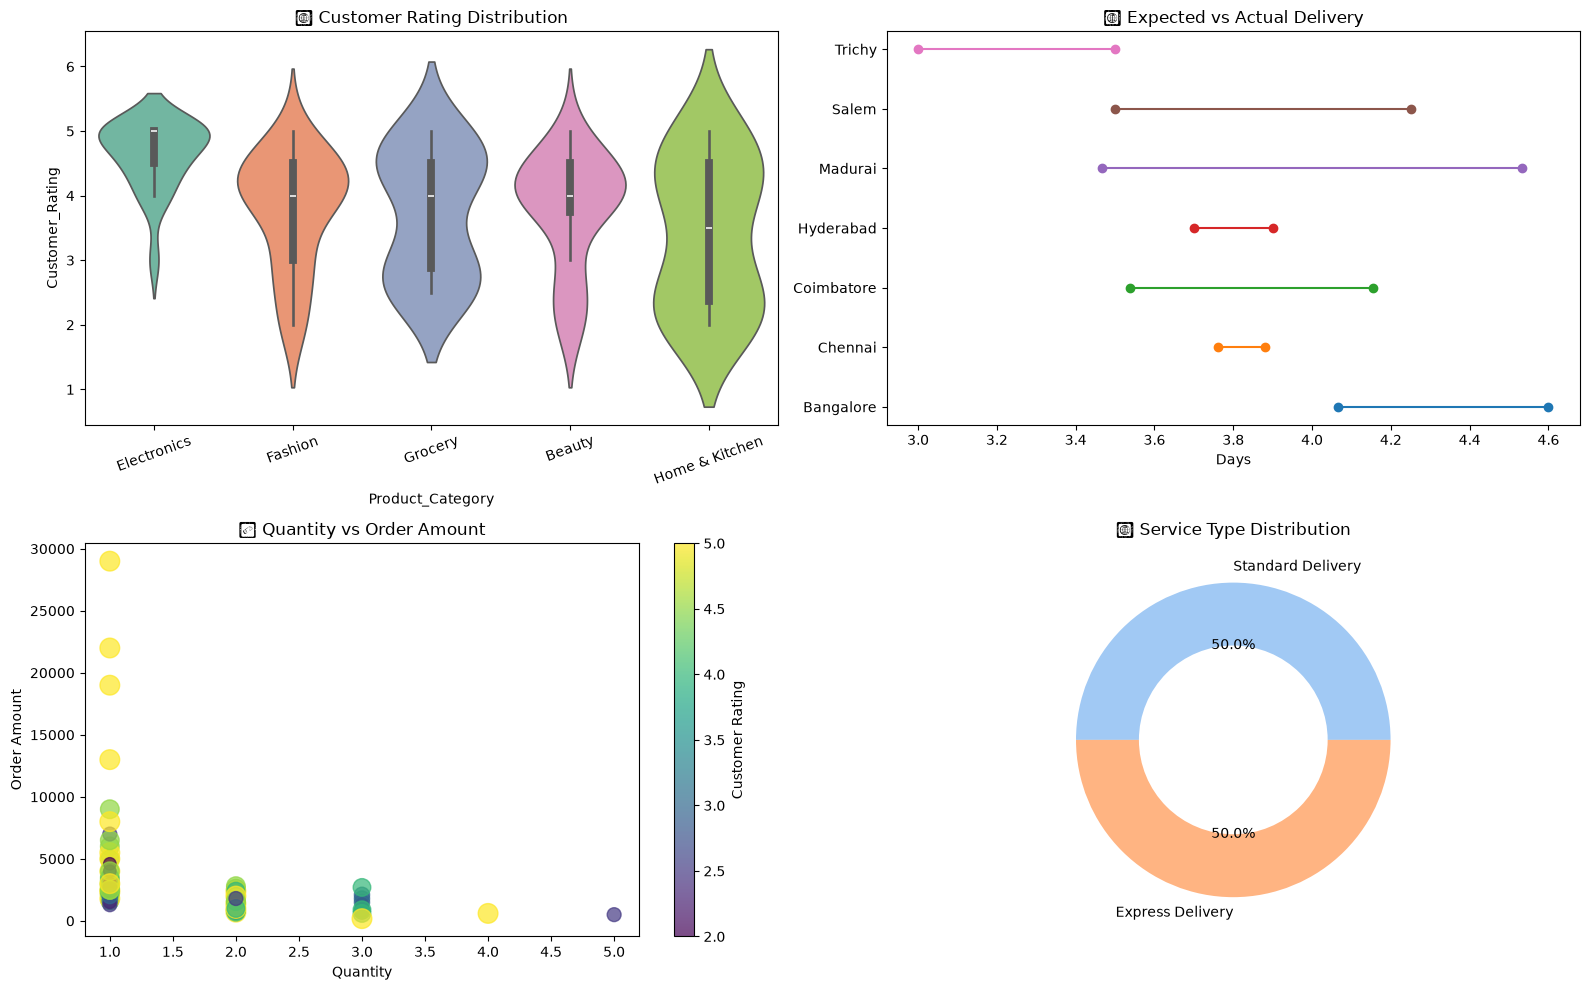

In [22]:
plt.figure(figsize=(16, 10))

# 1. Violin
plt.subplot(2, 2, 1)
sns.violinplot(
    x="Product_Category",
    y="Customer_Rating",
    data=df,
    palette="Set2",
    hue="Product_Category",
    legend=False
)
plt.title("🎻 Customer Rating Distribution")
plt.xticks(rotation=20)

# 2. Expected vs Actual
plt.subplot(2, 2, 2)

city_data = df.groupby("City")[["Expected_Delivery_Days", "Actual_Delivery_Days"]].mean()

for i in range(len(city_data)):
    plt.plot(
        [city_data["Expected_Delivery_Days"].iloc[i],
         city_data["Actual_Delivery_Days"].iloc[i]],
        [i, i],
        marker="o"
    )

plt.yticks(range(len(city_data)), city_data.index)
plt.title("🔗 Expected vs Actual Delivery")
plt.xlabel("Days")

# 3. Bubble
plt.subplot(2, 2, 3)

plt.scatter(
    df["Quantity"],
    df["Order_Amount"],
    s=df["Customer_Rating"] * 40,
    c=df["Customer_Rating"],
    cmap="viridis",
    alpha=0.7
)

plt.colorbar(label="Customer Rating")
plt.title("🫧 Quantity vs Order Amount")
plt.xlabel("Quantity")
plt.ylabel("Order Amount")

# 4. Donut
plt.subplot(2, 2, 4)

service_data = df["Service_Type"].value_counts()

plt.pie(
    service_data,
    labels=service_data.index,
    autopct="%1.1f%%",
    wedgeprops={"width": 0.4},
    colors=sns.color_palette("pastel")
)

plt.title("🍩 Service Type Distribution")

plt.tight_layout()
plt.show()

Business Intelligence Dashboard | 2026
Ecommerce_Delivery INNER JOIN Delivery_Partners

C:\Users\acer\AppData\Local\Temp\ipykernel_15636\2456670125.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, con)
C:\Users\acer\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


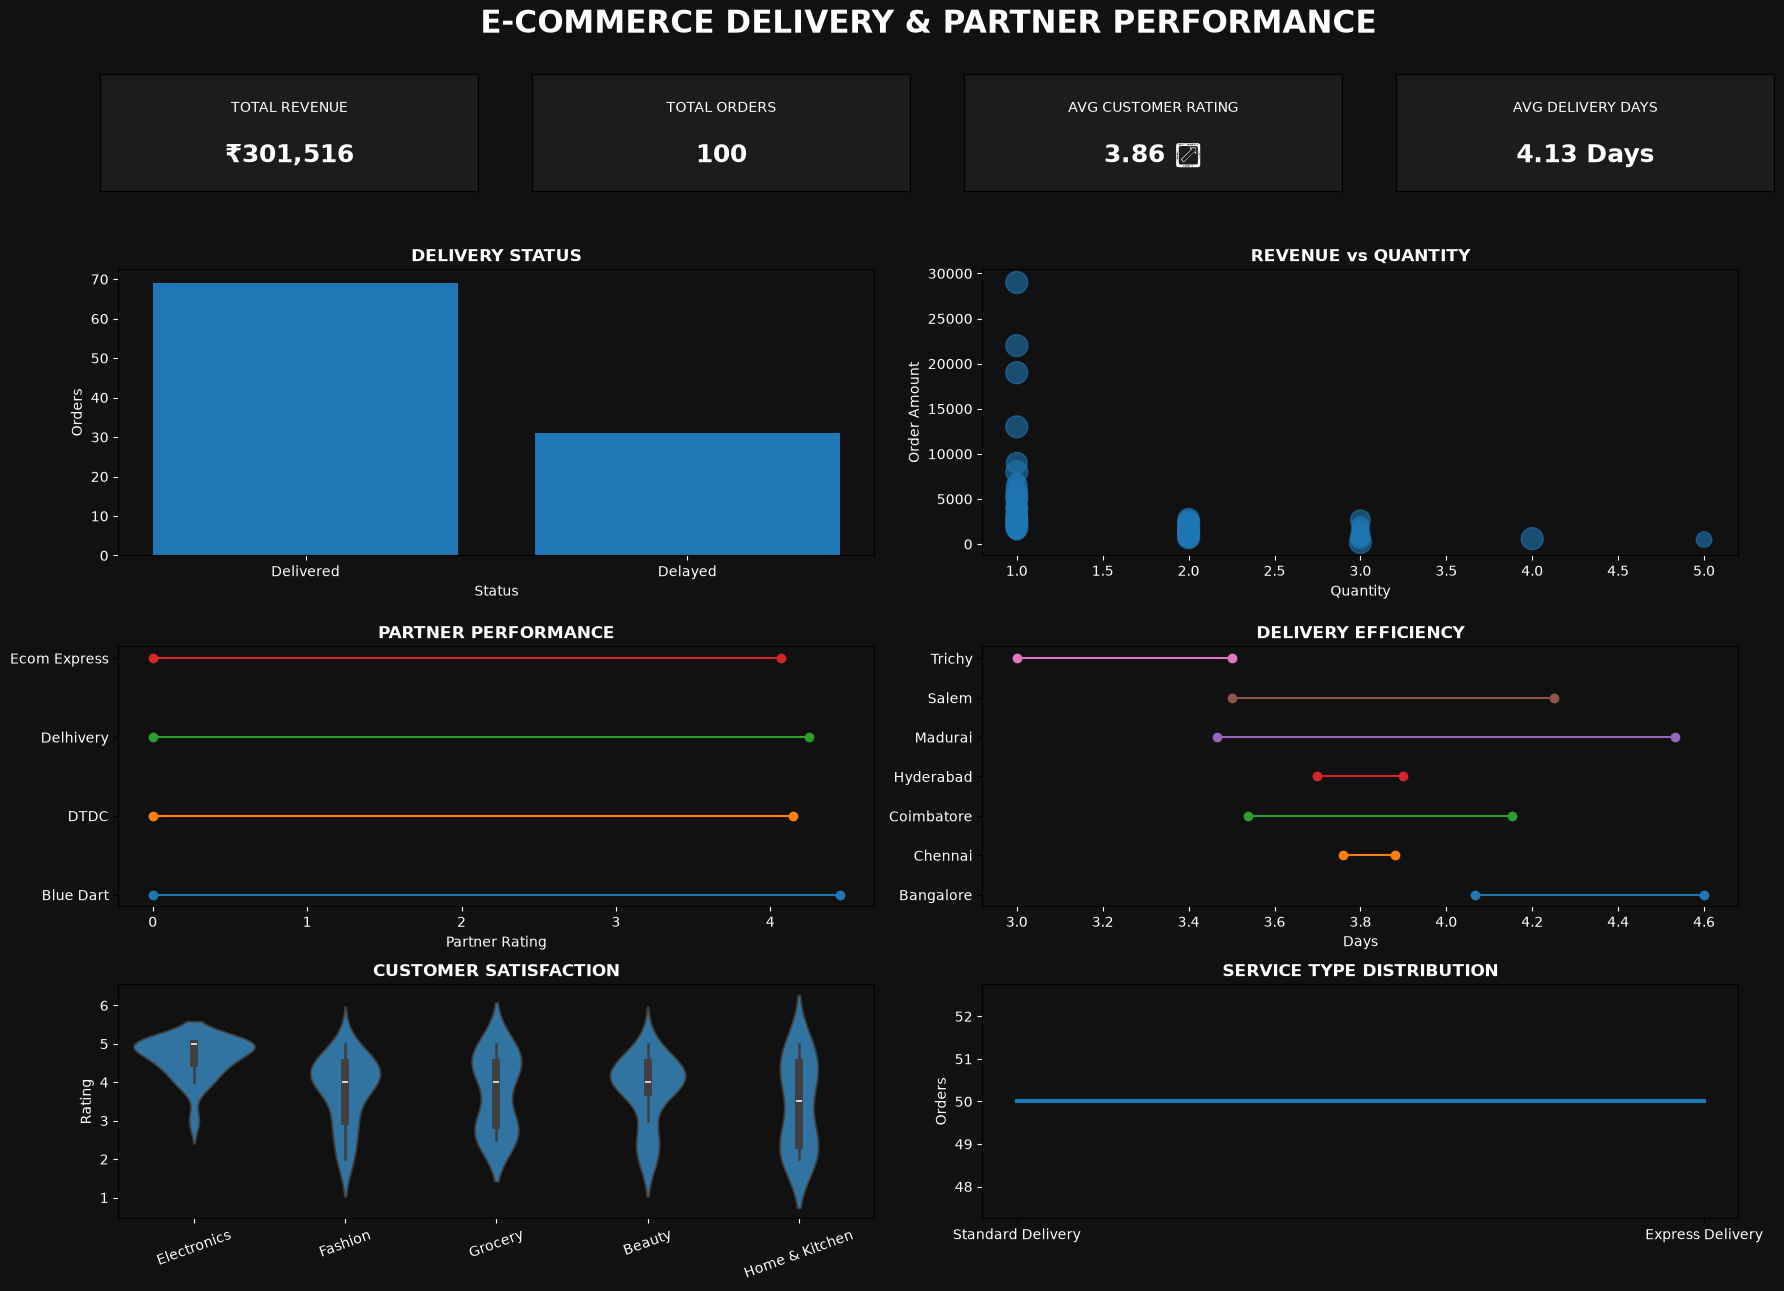

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# JOIN two tables
query = "SELECT e.Order_ID, e.Order_Date, e.Product_Category, e.Quantity, e.Order_Amount, e.Payment_Method, e.City, e.Expected_Delivery_Days, e.Actual_Delivery_Days, e.Delivery_Status, e.Customer_Rating, d.Delivery_Partner, d.Service_Type, d.Partner_Rating, d.Base_Delivery_Days, d.Service_City FROM Ecommerce_Delivery e INNER JOIN Delivery_Partners d ON e.Order_ID = d.Order_ID"

df = pd.read_sql(query, con)

# KPI values
total_revenue = df["Order_Amount"].sum()
total_orders = df["Order_ID"].nunique()
avg_rating = df["Customer_Rating"].mean()
avg_delivery = df["Actual_Delivery_Days"].mean()

# Dashboard
fig = plt.figure(figsize=(18, 13), facecolor="#111111")

fig.suptitle(
    "E-COMMERCE DELIVERY & PARTNER PERFORMANCE",
    fontsize=22,
    fontweight="bold",
    color="white",
    y=0.98
)

# KPI Cards
kpis = [
    ("TOTAL REVENUE", f"₹{total_revenue:,.0f}"),
    ("TOTAL ORDERS", f"{total_orders}"),
    ("AVG CUSTOMER RATING", f"{avg_rating:.2f} ⭐"),
    ("AVG DELIVERY DAYS", f"{avg_delivery:.2f} Days")
]

for i, (title, value) in enumerate(kpis):
    ax = fig.add_axes([0.04 + i * 0.24, 0.84, 0.21, 0.09])
    ax.set_facecolor("#1c1c1c")
    ax.text(0.5, 0.68, title, ha="center", color="white", fontsize=10)
    ax.text(0.5, 0.25, value, ha="center", color="white",
            fontsize=18, fontweight="bold")
    ax.set_xticks([])
    ax.set_yticks([])

# 1. Delivery Performance
ax1 = fig.add_axes([0.05, 0.56, 0.42, 0.22])
status = df["Delivery_Status"].value_counts()

ax1.bar(status.index, status.values)
ax1.set_title("DELIVERY STATUS", color="white", fontweight="bold")
ax1.set_xlabel("Status", color="white")
ax1.set_ylabel("Orders", color="white")
ax1.tick_params(colors="white")
ax1.set_facecolor("#111111")

# 2. Bubble Chart
ax2 = fig.add_axes([0.53, 0.56, 0.42, 0.22])

ax2.scatter(
    df["Quantity"],
    df["Order_Amount"],
    s=df["Customer_Rating"] * 50,
    alpha=0.6
)

ax2.set_title("REVENUE vs QUANTITY", color="white", fontweight="bold")
ax2.set_xlabel("Quantity", color="white")
ax2.set_ylabel("Order Amount", color="white")
ax2.tick_params(colors="white")
ax2.set_facecolor("#111111")

# 3. Partner Performance
ax3 = fig.add_axes([0.05, 0.29, 0.42, 0.20])

partner = df.groupby("Delivery_Partner")["Partner_Rating"].mean()

for i in range(len(partner)):
    ax3.plot(
        [0, partner.iloc[i]],
        [i, i],
        marker="o"
    )

ax3.set_yticks(range(len(partner)))
ax3.set_yticklabels(partner.index, color="white")
ax3.set_title("PARTNER PERFORMANCE", color="white", fontweight="bold")
ax3.set_xlabel("Partner Rating", color="white")
ax3.tick_params(axis="x", colors="white")
ax3.set_facecolor("#111111")

# 4. Delivery Efficiency
ax4 = fig.add_axes([0.53, 0.29, 0.42, 0.20])

city = df.groupby("City")[["Expected_Delivery_Days", "Actual_Delivery_Days"]].mean()

for i in range(len(city)):
    ax4.plot(
        [city["Expected_Delivery_Days"].iloc[i],
         city["Actual_Delivery_Days"].iloc[i]],
        [i, i],
        marker="o"
    )

ax4.set_yticks(range(len(city)))
ax4.set_yticklabels(city.index, color="white")
ax4.set_title("DELIVERY EFFICIENCY", color="white", fontweight="bold")
ax4.set_xlabel("Days", color="white")
ax4.tick_params(axis="x", colors="white")
ax4.set_facecolor("#111111")

# 5. Customer Satisfaction
ax5 = fig.add_axes([0.05, 0.05, 0.42, 0.18])

sns.violinplot(
    x="Product_Category",
    y="Customer_Rating",
    data=df,
    ax=ax5
)

ax5.set_title("CUSTOMER SATISFACTION", color="white", fontweight="bold")
ax5.set_xlabel("")
ax5.set_ylabel("Rating", color="white")
ax5.tick_params(axis="x", colors="white", rotation=20)
ax5.tick_params(axis="y", colors="white")
ax5.set_facecolor("#111111")

# 6. Service Type
ax6 = fig.add_axes([0.53, 0.05, 0.42, 0.18])

service = df["Service_Type"].value_counts()

ax6.step(
    range(len(service)),
    service.values,
    where="mid",
    linewidth=3
)

ax6.set_xticks(range(len(service)))
ax6.set_xticklabels(service.index, color="white")
ax6.set_title("SERVICE TYPE DISTRIBUTION", color="white", fontweight="bold")
ax6.set_ylabel("Orders", color="white")
ax6.tick_params(axis="y", colors="white")
ax6.set_facecolor("#111111")

plt.show()

?
💰 Total Revenue
📦 Total Orders
⭐ Average Customer Rating
🚚 Average Delivery Days
🔄 Delivery Status
🫧 Revenue vs Quantity Bubble
📍 Delivery Partner Performance
🔗 Expected vs Actual Delivery
🎻 Customer Satisfaction
📈 Service Type Distribution